In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('../data/raw/titanic.csv', index_col='PassengerId')

In [3]:
df.head(3)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [4]:
X = df.drop(columns=['Survived', 'Name'])
y = df['Survived']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle= True, stratify= y, random_state=0)

In [6]:
len(X_train), len(X_test)

(712, 179)

In [7]:
y_train.value_counts(normalize = True).round(2)

Survived
0    0.62
1    0.38
Name: proportion, dtype: float64

The dataset is slightly imbalansed

In [8]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 503 to 81
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    712 non-null    int64  
 1   Sex       712 non-null    object 
 2   Age       566 non-null    float64
 3   SibSp     712 non-null    int64  
 4   Parch     712 non-null    int64  
 5   Ticket    712 non-null    object 
 6   Fare      639 non-null    float64
 7   Cabin     160 non-null    object 
 8   Embarked  710 non-null    object 
dtypes: float64(2), int64(3), object(4)
memory usage: 55.6+ KB


Columns 'Age', 'Fare', 'Cabin', 'Embarked' have missing values

In [9]:
df.isna().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare         98
Cabin       687
Embarked      2
dtype: int64

In [10]:
def get_percentage_missing(df, axis):
    missing_rows = df.isna().sum(axis = axis)
    missing_rows_perc = np.round(missing_rows / df.shape[axis] * 100, 2)
    return missing_rows_perc[missing_rows_perc > 0]

In [11]:
get_percentage_missing(X_train, axis = 0)

Age         20.51
Fare        10.25
Cabin       77.53
Embarked     0.28
dtype: float64

The 'Cabin' column constists almost entirely of missing values

# Handling missing values

In [12]:
X_train.describe()

,Pclass,Age,SibSp,Parch,Fare
count,712.000000,566.000000,712.000000,712.000000,639.000000
mean,2.303371,29.469823,0.515449,0.363764,33.817070
std,0.835627,14.399015,1.059303,0.778387,54.818565
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,2.000000,20.000000,0.000000,0.000000,7.925000
50%,3.000000,28.000000,0.000000,0.000000,14.500000
75%,3.000000,38.000000,1.000000,0.000000,30.285400
max,3.000000,80.000000,8.000000,6.000000,512.329200


The 'Age' column is likely takes into account months (the minimum age in X_train is 8 months).

The 'Fare' column prices are historically accurate.

In [13]:
def histogram(df, col):

  plt.figure(figsize = (8,4))
  plt.hist(df[col], bins = 80, color = 'lightblue', edgecolor='black')
  plt.title(f'{col} distribution')
  plt.xlabel(col)
  plt.ylabel('Frequency')
  plt.show()

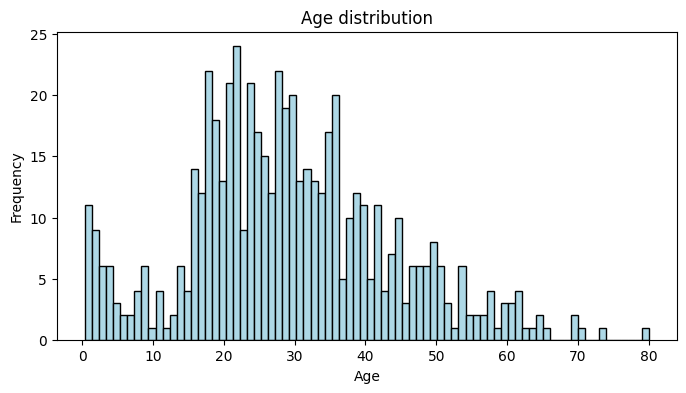

In [14]:
histogram(X_train, 'Age')

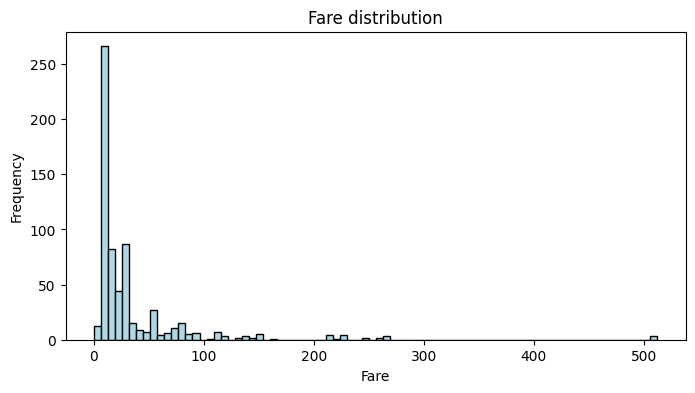

In [15]:
histogram(X_train, 'Fare')

The distributions are not normal. Imputing missing values per class with median instead of mean:

In [16]:
def impute_median_per_class(df, col):
    median_per_class = df.groupby('Pclass')[col].median().to_dict()
    df[col] = df[col].fillna(df['Pclass'].map(median_per_class))

In [17]:
impute_median_per_class(X_train, 'Age')
impute_median_per_class(X_train, 'Fare')
print(X_train.Age.isna().sum())
print(X_train.Fare.isna().sum())

0
0


In [18]:
X_train.describe(include = 'object')

,Sex,Ticket,Cabin,Embarked
count,712,712,160,710
unique,2,565,124,3
top,male,347082,B96 B98,S
freq,461,6,4,518


In [19]:
X_train['Ticket'] = X_train['Ticket'].str.strip()
X_train['Ticket'].duplicated().sum()

np.int64(147)

There are 144 duplicates of tickets, meaning some people were travelling using the same ticket

In [20]:
X_train['Cabin'].str[0].unique()

array([nan, 'D', 'B', 'E', 'C', 'A', 'F', 'G', 'T'], dtype=object)

In [21]:
X_train['Deck'] = X_train['Cabin'].str[0]
X_train = X_train.drop(columns = ['Cabin'])

The 'Deck' column reduces dimentionality and facilitates missing values imputation.

In [22]:
X_train.groupby('Pclass')['Deck'].value_counts()

Pclass  Deck
1       C       46
        B       44
        D       25
        E       18
        A        6
        T        1
2       F        5
        E        4
        D        3
3       F        3
        G        3
        E        2
Name: count, dtype: int64

Each class is associated with specific desks. To save information as it is, is best to impute values based on their distribution.

The 'T' category is not exactly a deck. Historically there was a single 'T' cabin, so it could be seen as an outlier.

As the 'T' cabin was located at the top, the closest category to it is an 'A' deck. Changing the category to preserve data distribution and imputing missing values:

In [23]:
X_train.loc[X_train['Deck'] == 'T', 'Deck'] = 'A'

In [ ]:
def get_column_distribution(df, column):
  return df[column].value_counts(normalize = True)


def missing_vals_imputation(df, col):
    df_dist = get_column_distribution(df, col)

    df_values = df_dist.index
    df_probs = df_dist.values

    missing_df_col_values = df[col].isna()
    df.loc[missing_df_col_values, col] = np.random.default_rng(seed=0).choice(df_values, size = missing_df_col_values.sum(), p = df_probs)

    return df

In [ ]:
X_train = missing_vals_imputation(X_train, 'Deck')
X_train.Deck.isna().sum()

np.int64(0)

In [25]:
X_train['Deck'] = X_train['Deck'].astype(pd.CategoricalDtype(categories=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T'], ordered=True))

In [26]:
utils.get_column_distribution(X_train, 'Embarked')

Embarked
S    0.729577
C    0.184507
Q    0.085915
Name: proportion, dtype: float64

In [27]:
X_train.Embarked.isna().sum()

np.int64(2)

The column has only two missing values, so creating a new category is not worth it.

The column has a dominant value 'S', therefore, imputing missing values with most frequent category.

In [28]:
embarked_mode = X_train.Embarked.mode()[0]
X_train.Embarked = X_train.Embarked.fillna(embarked_mode)
X_train.Embarked.isna().sum()

np.int64(0)

# Feature Enginering

Historically, passengers from different classes were accomodated in specific sections of the ship. 

First class occupied the midsection, second class was located towards the stern, and third class passengers were divided into single men at the bow and families and women at the stern. 

Based on this arrangement, a new feature called 'Section' can be created.

In [29]:
pclass_3_male_alone = X_train[(X_train['Pclass'] == 3) & (X_train['Parch'] == 0) & (X_train['Sex'] == 'male')]
pclass_3_male_alone.head(2)

,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
PassengerId,,,,,,,,,
465,3,male,24.0,0,0,A/S 2816,8.05,S,C
422,3,male,21.0,0,0,A/5. 13032,8.05,Q,C


In [30]:
pclass_3_other = X_train[(X_train['Pclass'] == 3) & ~(X_train.index.isin(pclass_3_male_alone.index))]
pclass_3_other.head(2)

,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
PassengerId,,,,,,,,,
503,3,female,24.0,0,0,330909,7.6292,Q,D
199,3,female,24.0,0,0,370370,7.7500,Q,C


In [31]:
pclass_1 = X_train[(X_train['Pclass'] == 1)]
pclass_1.head(2)

,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
PassengerId,,,,,,,,,
766,1,female,51.0,1,0,13502,77.9583,S,D
672,1,male,31.0,1,0,F.C. 12750,52.0000,S,B


In [32]:
for i in X_train.index:
  if i in pclass_3_male_alone.index:
    X_train.loc[i, 'Section'] = 'bow'
  elif i in pclass_3_other.index:
    X_train.loc[i, 'Section'] = 'stern'
  elif i in pclass_1.index:
    X_train.loc[i, 'Section'] = 'midship'
  else:
    X_train.loc[i, 'Section'] = 'midship_aft'

First-class ticket prices vary significantly, reflecting the differing wealth levels of the passengers. The minimum cost for a first-class ticket was £30, though the data includes much higher figures - such as £200. A new "Wealth_level" feature will indicate the wealth level of all individuals.

Also, the 'Fare' column represents the total ticket price for the group. Therefore, to accurately indicate the individuals' level of wealth, the price per person in cases of duplicates was calculated:

In [33]:
is_ticket_duplicated = X_train.Ticket.duplicated()
ticket_duplicates = X_train.loc[is_ticket_duplicated, 'Ticket'].unique()
people_on_ticket = X_train[X_train['Ticket'].isin(ticket_duplicates)]['Ticket'].value_counts()
people_on_ticket

Ticket
1601               6
347088             6
347082             6
CA 2144            5
382652             5
                  ..
W./C. 6607         2
S.C./PARIS 2079    2
113789             2
11668              2
C.A. 2673          2
Name: count, Length: 103, dtype: int64

In [34]:
X_train['People_On_Ticket'] = X_train['Ticket'].map(people_on_ticket).fillna(1).astype('int')
X_train['People_On_Ticket'].head(5)

PassengerId
503    1
465    1
199    1
766    2
422    1
Name: People_On_Ticket, dtype: int64

In [35]:
X_train['Fare_per_person'] = X_train['Fare'] / X_train['People_On_Ticket']
X_train = X_train.drop(columns = ['Fare', 'People_On_Ticket', 'Ticket'])

In [36]:
def boxplot(df, col):
    plt.figure(figsize=(12,4))
    sns.boxplot(data = df, x = col)
    plt.title(f"Boxplot of Fare_per_person")
    plt.ylabel("Value")
    plt.xticks(np.arange(0, 550, step=50))
    plt.tight_layout()
    plt.show()

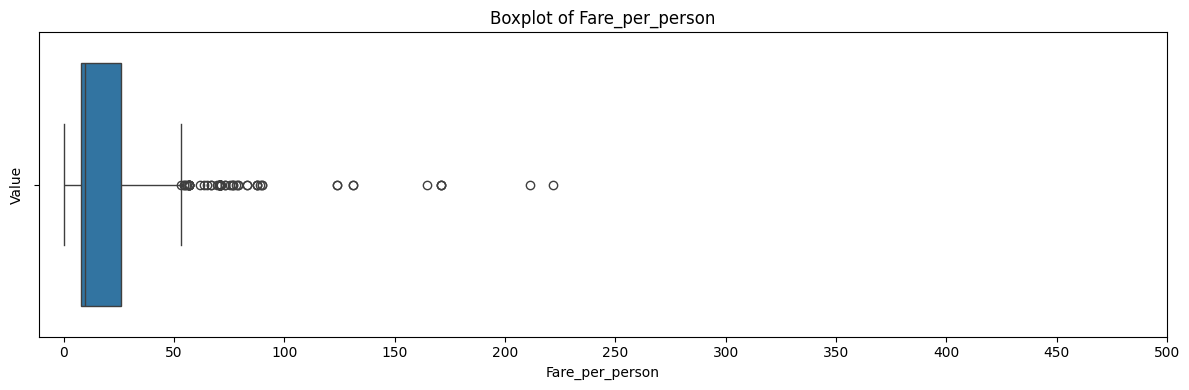

In [37]:
boxplot(X_train, 'Fare_per_person')

In [38]:
Q1 = X_train['Fare_per_person'].quantile(0.25)
Q3 = X_train['Fare_per_person'].quantile(0.75)
IQR = Q3-Q1
upper_bound = round(Q3 + (1.5 * IQR), 2)
upper_bound

np.float64(53.13)

The majority of the 'upper-class' fall within the range of £30 to £53.13. Values above upper bound are outliers, separated by gaps in the data. The £200 mark lies within such a gap, with the most extreme values appearing beyond it. Therefore, 200 serves as a suitable threshold between the 'wealthy' category (£53.13 to £200) and the 'elite' category.

In [39]:
for i in X_train.index:
  if X_train.loc[i, 'Fare_per_person'] >= 200:
    X_train.loc[i, 'Wealth_level'] = 'elite'
  elif (X_train.loc[i, 'Fare_per_person'] >= upper_bound) & (X_train.loc[i, 'Fare_per_person'] < 200):
    X_train.loc[i, 'Wealth_level'] = 'wealthy'
  elif (X_train.loc[i, 'Fare_per_person'] >= 30) & (X_train.loc[i, 'Fare_per_person'] < upper_bound):
    X_train.loc[i, 'Wealth_level'] = 'upper_class'
  elif (X_train.loc[i, 'Fare_per_person'] >= 12) & (X_train.loc[i, 'Fare_per_person'] < 30):
    X_train.loc[i, 'Wealth_level'] = 'middle_class'
  else:
    X_train.loc[i, 'Wealth_level'] = 'lower_class'

In [40]:
X_train['Wealth_level'] = X_train['Wealth_level'].astype(pd.CategoricalDtype(categories=['lower_class', 'middle_class', 'upper_class', 'wealthy', 'elite'], ordered=True))

The 'SibSp' and 'Patch' variables indicate the number of family members. 

Combining them into a 'Family_size' feature and add 1 to account for the passenger themselves:

In [41]:
X_train['Family_size'] = X_train['SibSp'] + X_train['Parch'] + 1
X_train = X_train.drop(columns = ['SibSp', 'Parch'])

In [42]:
X_train.head(2)

,Pclass,Sex,Age,Embarked,Deck,Section,Fare_per_person,Wealth_level,Family_size
PassengerId,,,,,,,,,
503,3,female,24.0,Q,D,stern,7.6292,lower_class,1
465,3,male,24.0,S,C,bow,8.0500,lower_class,1


# Data Visualization

In [43]:
numerical_cols = X_train.select_dtypes('number')
categorical_cols = X_train.select_dtypes(['object','category'])

In [44]:
def boxplots(df):

  fig, axis = plt.subplots(2, 3, figsize=(15, 10))
  axis = axis.flatten()

  for i, col in enumerate(df.columns):
    sns.boxplot(x=df[col], ax = axis[i], color='lightblue', linecolor="black")
    axis[i].set_xlabel(col)

  plt.tight_layout()
  plt.show()

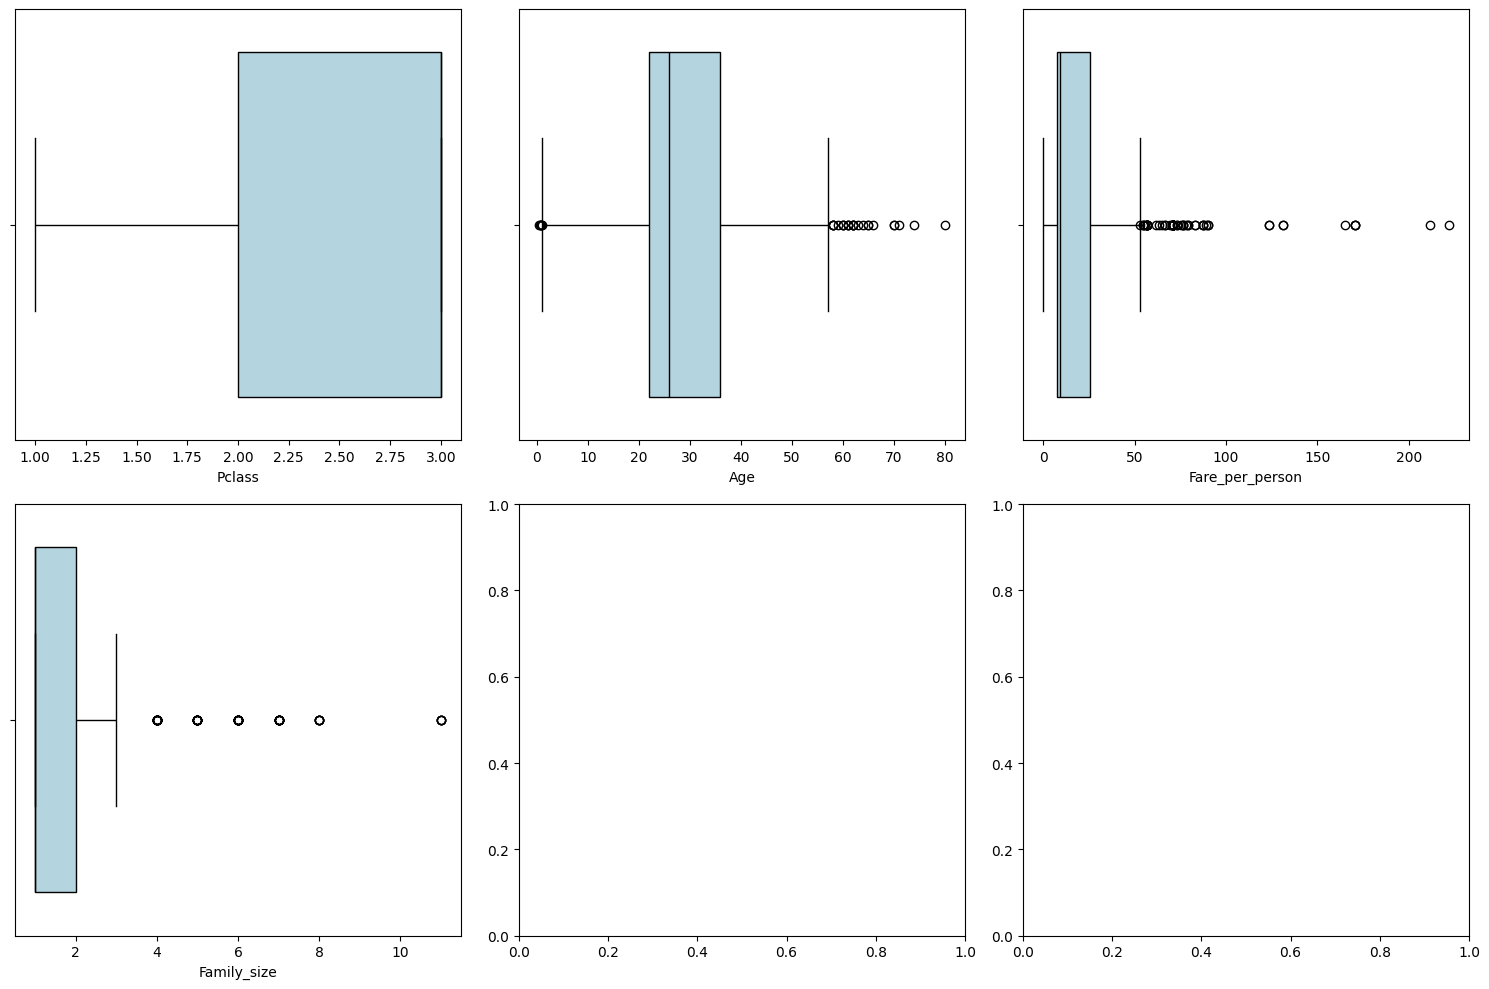

In [45]:
boxplots(numerical_cols)

It is important to retain ticket price information, even the outliers. The other variables also do not require the removal of outliers.

In [46]:
def barplots(df, y):
  fig, axis = plt.subplots((len(df.columns) + 1) // 2, 2, figsize=(10, 10))
  axis = axis.flatten()

  for i, col in enumerate(df.columns):
      sns.barplot(x=df[col], y=y, data=df, ax=axis[i], edgecolor='black', errorbar=None, color = 'lightblue')
      axis[i].set_title(f'Survival Rate by {col.capitalize()}')
      axis[i].set_xlabel(col.capitalize())
      axis[i].set_ylabel('Survival Rate')

  plt.tight_layout()
  plt.show()

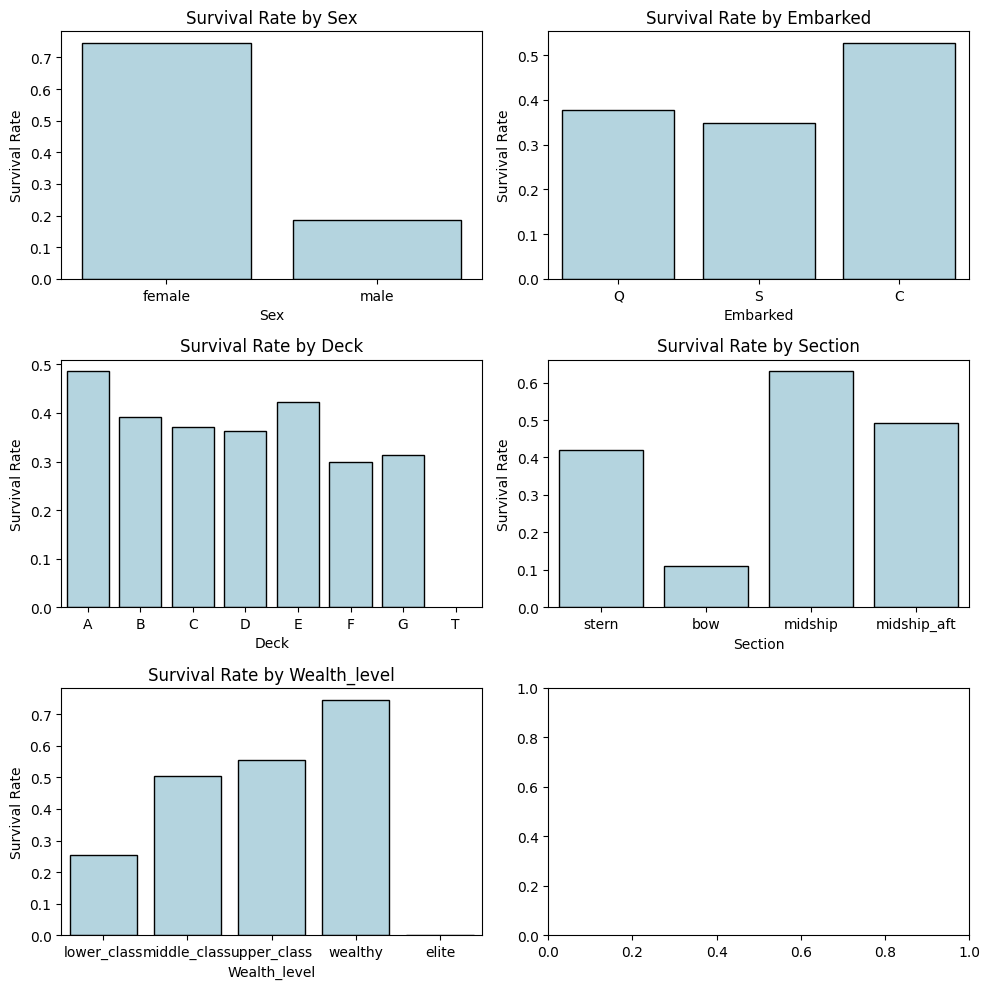

In [47]:
barplots(categorical_cols, y_train)

The charts show that women, the wealthy, and those located on the upper decks and in the middle section of the ship had a better chance of survival.

Men, the less wealthy, and those located on the lower decks and at the bow of the ship had the lowest chances.

In [48]:
numerical_cols['Age'] = pd.cut(numerical_cols['Age'], bins=4, labels=['0-20', '20-40', '40-60', '60-80'])

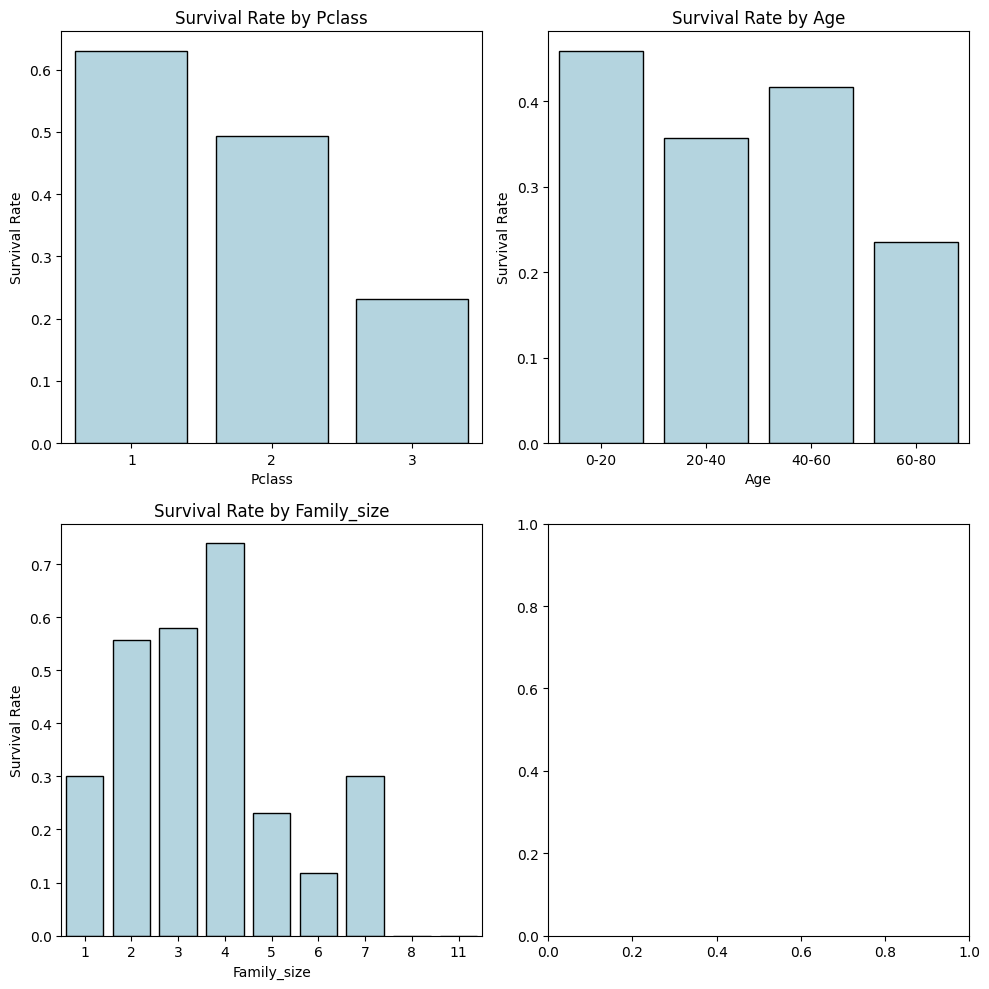

In [49]:
barplots(numerical_cols.drop(columns = ['Fare_per_person']), y_train)

The lowest chances of survival had third-class passengers, people aged 60 to 80, members of large families, and individuals traveling alone.

# Column encoding

Binary encoding for the 'Sex' variable:

In [50]:
mapping = {
    'male' : 1,
    'female' : 0
}

X_train['Is_Male'] = X_train['Sex'].map(mapping)
X_train = X_train.drop(columns = 'Sex')

One-hot encoding for the remaining nominal variables:

In [51]:
def one_hot_encoding(df, col):
  one_hot_encoded = pd.get_dummies(data = df, prefix = col, columns = [col], dtype = np.int32)
  return one_hot_encoded

In [52]:
X_train = one_hot_encoding(X_train, 'Section')
X_train = one_hot_encoding(X_train, 'Embarked')

Ordinal encoding for ordinal variables:

In [53]:
mapping = {
    'elite': 1,
    'wealthy': 2,
    'upper_class': 3,
    'middle_class': 4,
    'lower_class': 5,
}

X_train['Wealth_level'] = X_train['Wealth_level'].map(mapping)

In [54]:
labels_mapping = {
    k: i for i, k in enumerate(sorted(X_train['Deck'].unique()))
}

X_train['Deck'] = X_train['Deck'].map(labels_mapping)

In [55]:
X_train.head(5)

,Pclass,Age,Deck,Fare_per_person,Wealth_level,Family_size,Is_Male,Section_bow,Section_midship,Section_midship_aft,Section_stern,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,,,,
503,3,24.0,3.0,7.62920,5,1,0,0,0,0,1,0,1,0
465,3,24.0,2.0,8.05000,5,1,1,1,0,0,0,0,0,1
199,3,24.0,2.0,7.75000,5,1,0,0,0,0,1,0,1,0
766,1,51.0,3.0,38.97915,3,2,0,0,1,0,0,0,0,1
422,3,21.0,2.0,8.05000,5,1,1,1,0,0,0,0,1,0


# Feature scaling

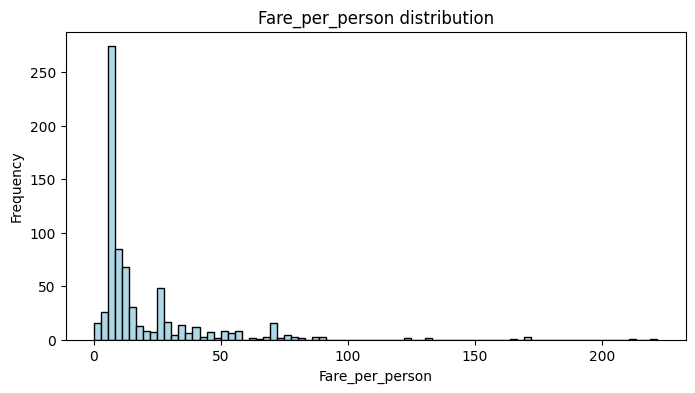

In [56]:
histogram(X_train, 'Fare_per_person')

Since the distribution of ticket prices ranges from zero to infinity and is right-skewed, a logarithmic transformation is used to change the variable's range of values:

In [57]:
def logarytm(df, col):
  df[f'{col}_log'] = np.log1p(df[col])
  df = df.drop(columns = [col])
  return df

In [58]:
X_train = logarytm(X_train, 'Fare_per_person')

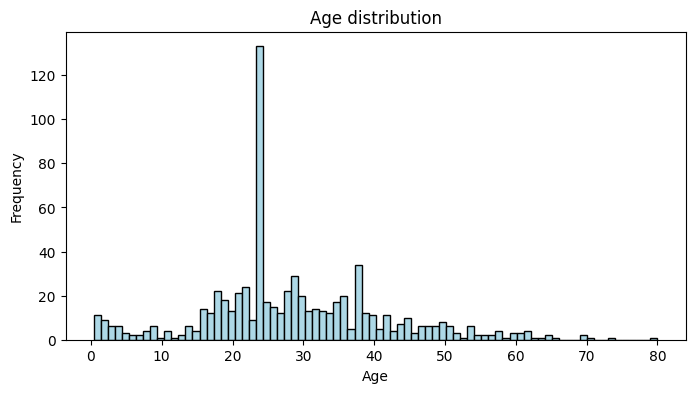

In [59]:
histogram(X_train, 'Age')

The distribution is right-skewed, which is why min-max normalization is used rather than standardization.

In [60]:
X_train['Age_normalized'] = (X_train['Age'] - X_train['Age'].min()) / (X_train['Age'].max() - X_train['Age'].min())
X_train = X_train.drop(columns = ['Age'])

# Result:

In [61]:
X_train.head()

,Pclass,Deck,Wealth_level,Family_size,Is_Male,Section_bow,Section_midship,Section_midship_aft,Section_stern,Embarked_C,Embarked_Q,Embarked_S,Fare_per_person_log,Age_normalized
PassengerId,,,,,,,,,,,,,,
503,3,3.0,5,1,0,0,0,0,1,0,1,0,2.155152,0.296306
465,3,2.0,5,1,1,1,0,0,0,0,0,1,2.202765,0.296306
199,3,2.0,5,1,0,0,0,0,1,0,1,0,2.169054,0.296306
766,1,3.0,3,2,0,0,1,0,0,0,0,1,3.688358,0.635587
422,3,2.0,5,1,1,1,0,0,0,0,1,0,2.202765,0.258608
